# StyleVector — End-Term Extension: Multi-Component PCA + Norm-Preserving Steering

**Goal of this notebook:** evaluate our proposed extension to StyleVector against
the paper's own Mean Difference method, using a controlled **2×2 ablation**:

|  | No norm-preserving | With norm-preserving |
|---|---|---|
| **Single vector (k=1)** | Paper's method (midterm baseline) | Ablation A |
| **Multi-component (k>1)** | Ablation B | **Our full proposed method** |

This isolates the individual contribution of each modification, as promised in
the midterm report's roadmap. All four conditions use the **same** validated
layer and steering strength $\alpha$ per task (from the midterm grid search) --
only $k$ (number of PCA components) and whether steering is norm-preserving
differ between conditions, so any difference in results is attributable to
those two factors alone, not to re-tuned hyperparameters.

### What's reused from the midterm notebook (unchanged, validated)
- Model: LLaMA-2-7B-chat, 4-bit (NF4) quantization
- LaMP data loading, shuffle seed, per-task history caps
- Exact paper prompts (Appendix E)
- Validated `(layer, alpha)` per task

### What's new here
- `vectors_from_deltas`: returns **both** the plain Mean Difference vector
  (Eq. 7 in the paper) **and** our multi-component PCA combination from the
  same underlying contrastive deltas -- computed once per user, reused for
  all 4 conditions, so this notebook does not cost 4x the midterm run.
- Norm-preserving steering: rescales the steered activation back to its
  original magnitude after the additive intervention (Eq. 11), targeting the
  activation-magnitude instability the paper's own Fig. 3 documents.

### Bug-fix carried forward
The prompt-construction bug identified during the midterm phase (double-wrapping
an already-rendered LaMP query) is fixed from the start in this notebook --
benchmark-mode queries use `u["query_input"]` directly, never re-wrapped
through the prompt template.


## Part 0 — Environment Setup

In [1]:
# Cell 0.1 — Working directory (local lab PC)
import os
PROJECT_DIR = os.path.expanduser('~/stylevector_project')
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)
print("Working directory:", os.getcwd())

Working directory: /home/user/stylevector_project


In [2]:
# Cell 0.2 — Install dependencies
!pip install -q transformers accelerate bitsandbytes rouge-score nltk huggingface_hub --upgrade


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
# Cell 0.3 — NLTK data (with fallback if blocked)
import os
os.environ["NLTK_ALLOW_PROXIED_URLOPEN"] = "1"
import nltk
try:
    nltk.pathsec.ALLOW_PROXIED_FETCH = True
except AttributeError:
    pass

NLTK_OK = True
try:
    nltk.download('wordnet', quiet=True)
    nltk.download('punkt', quiet=True)
    nltk.download('punkt_tab', quiet=True)
    nltk.download('omw-1.4', quiet=True)
    from nltk import word_tokenize
    from nltk.translate.meteor_score import meteor_score
    _ = word_tokenize("test sentence")
    _ = meteor_score([["test", "sentence"]], ["test", "sentence"])
    print("NLTK data OK -- using real METEOR + real tokenizer.")
except Exception as e:
    NLTK_OK = False
    print(f"NLTK data unavailable ({e}). Falling back to unigram-F1 METEOR proxy.")


/home/user/stylevector_env/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/user/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


NLTK data OK -- using real METEOR + real tokenizer.


In [4]:
# Cell 0.4 — Imports
import json, time, re, random
from pathlib import Path

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import logging
logging.getLogger("transformers").setLevel(logging.ERROR)

plt.rcParams["figure.dpi"] = 110
RNG_SEED = 42
print("Imports OK. CUDA available:", torch.cuda.is_available())

Imports OK. CUDA available: True


/home/user/stylevector_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1 — Download & Load LaMP (dev split)

In [5]:
%%writefile download_lamp.sh
#!/usr/bin/env bash
set -euo pipefail
OUT_DIR="${1:-./data/lamp}"
BASE_URL="https://ciir.cs.umass.edu/downloads/LaMP"

declare -A TASKS=(
  [LaMP_4]="News Headline Generation"
  [LaMP_5]="Scholarly Title Generation"
  [LaMP_7]="Tweet Paraphrasing"
)
SPLITS=(train dev test)
FILE_TYPES=(questions outputs)

for task in "${!TASKS[@]}"; do
  echo "== ${task}: ${TASKS[$task]} =="
  for split in "${SPLITS[@]}"; do
    mkdir -p "${OUT_DIR}/${task}/${split}"
    for ftype in "${FILE_TYPES[@]}"; do
      url="${BASE_URL}/${task}/${split}/${split}_${ftype}.json"
      out="${OUT_DIR}/${task}/${split}/${split}_${ftype}.json"
      if [ -f "${out}" ]; then
        echo "  [cached] ${out}"
        continue
      fi
      echo "  fetching ${url}"
      if curl -sSf --retry 3 --max-time 60 -o "${out}" "${url}"; then
        echo "    saved -> ${out}"
      else
        echo "    [skip] not publicly available: ${url}"
        rm -f "${out}"
      fi
    done
  done
done
echo "Done."


Overwriting download_lamp.sh


In [6]:
# Cell 1.2 — Run the download (idempotent, safe to re-run -- will mostly hit [cached])
!bash download_lamp.sh ./data/lamp
!ls -la ./data/lamp/LaMP_5/dev/

== LaMP_7: Tweet Paraphrasing ==
  [cached] ./data/lamp/LaMP_7/train/train_questions.json
  [cached] ./data/lamp/LaMP_7/train/train_outputs.json
  [cached] ./data/lamp/LaMP_7/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_7/dev/dev_outputs.json
  [cached] ./data/lamp/LaMP_7/test/test_questions.json
  [cached] ./data/lamp/LaMP_7/test/test_outputs.json
== LaMP_4: News Headline Generation ==
  [cached] ./data/lamp/LaMP_4/train/train_questions.json
  [cached] ./data/lamp/LaMP_4/train/train_outputs.json
  [cached] ./data/lamp/LaMP_4/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_4/dev/dev_outputs.json
  [cached] ./data/lamp/LaMP_4/test/test_questions.json
  [cached] ./data/lamp/LaMP_4/test/test_outputs.json
== LaMP_5: Scholarly Title Generation ==
  [cached] ./data/lamp/LaMP_5/train/train_questions.json
  [cached] ./data/lamp/LaMP_5/train/train_outputs.json
  [cached] ./data/lamp/LaMP_5/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_5/dev/dev_outputs.json
  [cached] ./data/lamp/

In [7]:
%%writefile load_lamp_data.py
import json
from pathlib import Path
from typing import Optional

TASK_PROFILE_FIELDS = {
    "LaMP_4": ("text", "title"),
    "LaMP_5": ("abstract", "title"),
    "LaMP_7": (None, "text"),
}


def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def build_gold_lookup(outputs_json: dict) -> dict:
    return {item["id"]: item["output"] for item in outputs_json["golds"]}


def make_synthetic_input(y_text: str) -> str:
    return "Write a short tweet."


def load_task_split(data_dir: Path, task: str, split: str,
                     max_users: Optional[int] = None,
                     max_history_per_user: Optional[int] = None,
                     min_history_len: int = 3):
    assert task in TASK_PROFILE_FIELDS, f"Unsupported task: {task}"
    input_field, output_field = TASK_PROFILE_FIELDS[task]

    q_path = data_dir / task / split / f"{split}_questions.json"
    o_path = data_dir / task / split / f"{split}_outputs.json"

    questions = load_json(q_path)
    gold_lookup = {}
    if o_path.exists():
        gold_lookup = build_gold_lookup(load_json(o_path))

    for q in questions:
        if q["profile"]:
            sample = q["profile"][0]
            print(f"[{task}/{split}] sample profile item keys: {list(sample.keys())}")
            if output_field not in sample:
                raise KeyError(f"Expected output field '{output_field}' not found in {sample}")
            break

    users = {}
    for q in questions:
        user_id = q["id"]
        history = []
        for item in q["profile"]:
            y_i = item.get(output_field)
            if y_i is None:
                continue
            x_i = item.get(input_field) if input_field is not None else make_synthetic_input(y_i)
            history.append((x_i, y_i))

        if len(history) < min_history_len:
            continue
        if max_history_per_user is not None:
            history = history[:max_history_per_user]

        gold = gold_lookup.get(user_id)
        if gold is None:
            continue

        users[user_id] = {"history": history, "query_input": q["input"], "query_gold": gold}
        if max_users is not None and len(users) >= max_users:
            break

    return users


Overwriting load_lamp_data.py


In [8]:
# Cell 1.4 — Load all 3 tasks, per-task history cap, shuffled (same seed as midterm)
from load_lamp_data import load_task_split
from pathlib import Path

TASKS = ["LaMP_4", "LaMP_5", "LaMP_7"]
DATA_DIR = Path("./data/lamp")

# Same per-task history caps as the midterm notebook, for direct comparability.
MAX_HISTORY_PER_USER_BY_TASK = {
    "LaMP_4": 15,
    "LaMP_5": 15,
    "LaMP_7": 15,
}

N_EVAL_USERS_CAP = 300   # <-- scope knob; raise after the timing test in Part 4 confirms feasibility.
                          #     This run does 5 generations/user (vs. 2 in the midterm run), so
                          #     start more conservatively than your final midterm n.

eval_users = {}
for task in TASKS:
    cap = MAX_HISTORY_PER_USER_BY_TASK[task]
    pool = load_task_split(
        data_dir=DATA_DIR, task=task, split="dev",
        max_users=None, max_history_per_user=cap, min_history_len=3,
    )
    all_ids = list(pool.keys())
    random.Random(RNG_SEED).shuffle(all_ids)   # same seed as midterm -> same user order

    eval_ids = all_ids[:N_EVAL_USERS_CAP]
    eval_users[task] = {uid: pool[uid] for uid in eval_ids}

    avg_hist = np.mean([len(u["history"]) for u in eval_users[task].values()])
    print(f"{task}: pool={len(pool)}, eval={len(eval_users[task])} users, "
          f"history_cap={cap}, avg_actual_history={avg_hist:.1f}")


[LaMP_4/dev] sample profile item keys: ['text', 'title', 'id']
LaMP_4: pool=1925, eval=300 users, history_cap=15, avg_actual_history=14.1
[LaMP_5/dev] sample profile item keys: ['title', 'abstract', 'id']
LaMP_5: pool=2500, eval=300 users, history_cap=15, avg_actual_history=15.0
[LaMP_7/dev] sample profile item keys: ['text', 'id']
LaMP_7: pool=1500, eval=300 users, history_cap=15, avg_actual_history=12.5


## Part 2 — Load LLaMA-2-7B-chat (4-bit, same as midterm)

Requires a HuggingFace token with approved access to `meta-llama/Llama-2-7b-chat-hf`,
already cached via `huggingface-cli login` on this machine.

In [9]:
# Cell 2.1 — Clean up any stale GPU memory from a previous session first
import gc, torch
for var_name in ["model", "tokenizer"]:
    if var_name in dir():
        del globals()[var_name]
gc.collect()
torch.cuda.empty_cache()
if torch.cuda.is_available():
    print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")
    print(f"GPU memory reserved:  {torch.cuda.memory_reserved()/1e9:.2f} GB")


GPU memory allocated: 0.00 GB
GPU memory reserved:  0.00 GB


In [10]:
# Cell 2.2 — Load tokenizer + model (4-bit NF4, matching the midterm run)
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

MODEL_NAME = "meta-llama/Llama-2-7b-chat-hf"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    device_map="auto",
    quantization_config=quant_config,
)
model.eval()
model.generation_config.max_length = 1024

N_LAYERS = len(model.model.layers)
HIDDEN_DIM = model.config.hidden_size
print(f"Loaded {MODEL_NAME}")
print(f"Layers: {N_LAYERS} | Hidden dim: {HIDDEN_DIM}")
print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")

Loading weights: 100%|██████████| 291/291 [00:15<00:00, 18.69it/s]

Loaded meta-llama/Llama-2-7b-chat-hf
Layers: 32 | Hidden dim: 4096
GPU memory allocated: 4.19 GB


In [11]:
# Cell 2.3 — Prompt formatting (chat template, [INST] fallback)
def build_input_ids(tokenizer, prompt, device):
    messages = [{"role": "user", "content": prompt}]
    try:
        inputs = tokenizer.apply_chat_template(
            messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
        )
        return inputs["input_ids"].to(device)
    except Exception:
        formatted = f"<s>[INST] {prompt} [/INST]"
        return tokenizer(formatted, return_tensors="pt").input_ids.to(device)

_test = build_input_ids(tokenizer, "Say hello.", model.device)
print("Prompt formatting OK, input shape:", _test.shape)

Prompt formatting OK, input shape: torch.Size([1, 11])


## Part 3 — Core Machinery: Generation, Activations, Style Vectors, Steering

**Important:** the top-level evaluation query (`query_input`) is LaMP's own
pre-rendered prompt. It is used **as-is**, never re-wrapped through
`TASK_PROMPTS` -- this is the midterm bug fix, carried forward from the start.
`TASK_PROMPTS` is only applied to raw history-item text (`x_i`), which is
genuinely unrendered.

In [12]:
# Cell 3.1 — Task prompts (exact wording from the paper's Appendix E) --
# used ONLY for history items (x_i), never for query_input (see note above).
TASK_PROMPTS = {
    "LaMP_4": lambda text: f'Generate a headline for the following article "{text}".',
    "LaMP_5": lambda text: f'Generate a title for the following abstract of a paper "{text}".',
    "LaMP_7": lambda text: f'Paraphrase the following tweet without any explanation before or after it "{text}".',
}

In [13]:
# Cell 3.2 — Plain (unsteered) generation
def generate_text(model, tokenizer, prompt, max_new_tokens=40, do_sample=False):
    input_ids = build_input_ids(tokenizer, prompt, model.device)
    with torch.no_grad():
        out = model.generate(
            input_ids, max_new_tokens=max_new_tokens,
            do_sample=do_sample, pad_token_id=tokenizer.eos_token_id,
        )
    gen_tokens = out[0][input_ids.shape[1]:]
    return tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()

In [14]:
# Cell 3.3 — Last-token activation extraction at a given layer (Eq. 5)
def get_last_token_activation(model, tokenizer, text, layer_idx, max_len=512):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=max_len).to(model.device)
    captured = {}
    def hook(module, inp, output):
        hs = output[0] if isinstance(output, tuple) else output
        captured["hidden"] = hs[:, -1, :].detach().float().cpu()
    handle = model.model.layers[layer_idx].register_forward_hook(hook)
    try:
        with torch.no_grad():
            model(**inputs)
    finally:
        handle.remove()
    return captured["hidden"].squeeze(0)

In [15]:
# Cell 3.4 — Contrastive deltas (Eq. 5): returns the RAW per-history-item
# deltas (not just their mean), so both the plain Mean Difference vector AND
# the multi-component PCA vector can be derived from a SINGLE expensive pass
# over this user's history -- computed once, reused for all 4 ablation conditions.
def compute_user_deltas(model, tokenizer, history, task, layer_idx,
                         max_history=15, max_gen_tokens=40):
    prompt_fn = TASK_PROMPTS[task]
    history = history[:max_history]
    deltas = []
    for x_i, y_i in history:
        if not x_i or not y_i:
            continue
        y_hat_i = generate_text(model, tokenizer, prompt_fn(x_i), max_new_tokens=max_gen_tokens)
        a_p = get_last_token_activation(model, tokenizer, f"{x_i} {y_i}", layer_idx)
        a_n = get_last_token_activation(model, tokenizer, f"{x_i} {y_hat_i}", layer_idx)
        deltas.append(a_p - a_n)
    if len(deltas) == 0:
        return None
    return torch.stack(deltas)  # (n_history, hidden_dim)

In [16]:
# Cell 3.5 — Build BOTH style vectors from the same deltas:
#   mean_vec  -- the paper's Mean Difference (Eq. 7), k=1
#   ours_vec  -- our extension: top-k PCA over {delta_i} U {-delta_i}, combined
#                with variance-proportional weights, rescaled to match
#                mean_vec's norm so alpha means the same thing for both
#                (verified with synthetic tensors before being used here --
#                k=1 degenerates exactly to mean_vec; norms match by construction).
def vectors_from_deltas(deltas, k=3):
    mean_vec = deltas.mean(dim=0)
    mean_norm = mean_vec.norm()

    info = {"n_history": deltas.shape[0], "mean_norm": mean_norm.item()}

    if k <= 1 or deltas.shape[0] < 2:
        return mean_vec, mean_vec.clone(), info

    aug = torch.cat([deltas, -deltas], dim=0)          # symmetric set {delta_i} U {-delta_i}
    aug = aug - aug.mean(dim=0, keepdim=True)
    U, S, Vt = torch.linalg.svd(aug, full_matrices=False)
    k_eff = min(k, Vt.shape[0])
    top_vectors = Vt[:k_eff]
    explained = (S[:k_eff] ** 2)
    explained = explained / explained.sum()

    # Fix SVD sign ambiguity: align each component with the mean direction
    signed_vectors = []
    for j in range(k_eff):
        v = top_vectors[j]
        if torch.dot(v, mean_vec) < 0:
            v = -v
        signed_vectors.append(v)
    signed_vectors = torch.stack(signed_vectors)

    weights = torch.sqrt(explained)
    weights = weights / weights.sum()
    combined = (weights.unsqueeze(1) * signed_vectors).sum(dim=0)

    # Rescale to match mean_vec's norm -- without this, a weighted sum of
    # orthonormal unit vectors has a different norm than mean_vec, which
    # would make the same alpha mean different things for the two methods.
    combined = combined / combined.norm().clamp(min=1e-8) * mean_norm

    info["explained_variance_ratio"] = explained.tolist()
    info["k_components"] = k_eff
    return mean_vec, combined, info

In [17]:
# Cell 3.6 — Steering hook (Eq. 11) with an optional norm-preserving variant.
# norm_preserving=True rescales the steered activation back to its ORIGINAL
# magnitude after the additive intervention, targeting the activation-magnitude
# instability the paper's own Fig. 3 documents at high steering strength.
def make_steering_hook(direction, alpha, norm_preserving=False):
    direction = direction.clone()

    def hook(module, inp, output):
        hs = output[0] if isinstance(output, tuple) else output
        vec = (alpha * direction).to(hs.dtype).to(hs.device)

        hs = hs.clone()
        last = hs[:, -1, :]

        if norm_preserving:
            orig_norm = last.norm(dim=-1, keepdim=True)
            new_last = last + vec
            new_norm = new_last.norm(dim=-1, keepdim=True).clamp(min=1e-6)
            new_last = new_last * (orig_norm / new_norm)
        else:
            new_last = last + vec

        hs[:, -1, :] = new_last
        return (hs,) + output[1:] if isinstance(output, tuple) else hs

    return hook


def generate_with_steering(model, tokenizer, prompt, layer_idx, direction, alpha,
                            norm_preserving=False, max_new_tokens=40):
    input_ids = build_input_ids(tokenizer, prompt, model.device)
    handle = model.model.layers[layer_idx].register_forward_hook(
        make_steering_hook(direction, alpha, norm_preserving)
    )
    try:
        with torch.no_grad():
            out = model.generate(
                input_ids, max_new_tokens=max_new_tokens,
                do_sample=False, pad_token_id=tokenizer.eos_token_id,
            )
    finally:
        handle.remove()
    gen_tokens = out[0][input_ids.shape[1]:]
    return tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()

In [18]:
# Cell 3.7 — Evaluation metrics
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)

def _simple_tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

def _simple_meteor_proxy(pred_tokens, gold_tokens):
    if not pred_tokens or not gold_tokens:
        return 0.0
    matches = sum(1 for t in pred_tokens if t in gold_tokens)
    precision = matches / len(pred_tokens)
    recall = matches / len(gold_tokens)
    if precision + recall == 0:
        return 0.0
    return (2 * precision * recall) / (precision + recall)

if NLTK_OK:
    from nltk import word_tokenize
    from nltk.translate.meteor_score import meteor_score as _real_meteor

def score_pair(pred, gold):
    rouge_l = scorer.score(gold, pred)['rougeL'].fmeasure
    if NLTK_OK:
        meteor = _real_meteor([word_tokenize(gold)], word_tokenize(pred))
    else:
        meteor = _simple_meteor_proxy(_simple_tokenize(pred), _simple_tokenize(gold))
    return rouge_l, meteor

print("Metric functions ready. Using", "REAL METEOR" if NLTK_OK else "FALLBACK METEOR proxy")

Metric functions ready. Using REAL METEOR


## Part 4 — Configuration (Reused Hyperparameters, No Re-Tuning)

Layer and $\alpha$ are reused **unchanged** from the midterm's validated grid
search, for all 4 ablation conditions -- so any difference between conditions
is attributable only to $k$ and norm-preserving, not to different tuning.

In [19]:
# Cell 4.1 — Hardcoded config (same as midterm) + extension-specific settings
BEST_CONFIG = {
    "LaMP_4": {"layer": 16, "alpha": 0.25},
    "LaMP_5": {"layer": 16, "alpha": 0.50},
    "LaMP_7": {"layer": 16, "alpha": 0.50},
}

MAX_GEN_TOKENS_PER_TASK = {
    "LaMP_4": 40,
    "LaMP_5": 40,
    "LaMP_7": 40,
}

K_COMPONENTS = 3   # number of PCA components for the multi-component conditions

print("BEST_CONFIG:", json.dumps(BEST_CONFIG, indent=2))
print("K_COMPONENTS:", K_COMPONENTS)

BEST_CONFIG: {
  "LaMP_4": {
    "layer": 16,
    "alpha": 0.25
  },
  "LaMP_5": {
    "layer": 16,
    "alpha": 0.5
  },
  "LaMP_7": {
    "layer": 16,
    "alpha": 0.5
  }
}
K_COMPONENTS: 3


In [20]:
# Cell 4.2 — Checkpoint/results directory + resumable helpers
CHECKPOINT_DIR = Path("./checkpoints_endterm")
CHECKPOINT_DIR.mkdir(exist_ok=True)

def checkpoint_path(task):
    return CHECKPOINT_DIR / f"results_{task}.jsonl"

def load_checkpoint(task):
    path = checkpoint_path(task)
    done = {}
    if path.exists():
        with open(path, "r") as f:
            for line in f:
                if line.strip():
                    row = json.loads(line)
                    done[row["user_id"]] = row
    return done

def append_checkpoint(task, row):
    with open(checkpoint_path(task), "a") as f:
        f.write(json.dumps(row) + "\n")

print("Checkpoint directory:", CHECKPOINT_DIR.resolve())

Checkpoint directory: /home/user/stylevector_project/checkpoints_endterm


In [21]:
# Cell 4.3 — Main evaluation function: 1 baseline + 4 steered conditions per user,
# sharing ONE pass over history (Cell 3.4) and TWO derived vectors (Cell 3.5).
def run_task_evaluation(task, users, cfg, k_components, verbose_every=20):
    max_gen_tokens = MAX_GEN_TOKENS_PER_TASK[task]
    max_history = MAX_HISTORY_PER_USER_BY_TASK[task]
    layer_idx, alpha = cfg["layer"], cfg["alpha"]

    user_ids = list(users.keys())
    already_done = load_checkpoint(task)

    n_new = 0
    for i, uid in enumerate(tqdm(user_ids, desc=f"{task}")):
        if uid in already_done:
            continue
        u = users[uid]
        try:
            prompt = u["query_input"]     # LaMP's own rendered prompt -- used as-is (bug fix)
            gold = u["query_gold"]

            pred_base = generate_text(model, tokenizer, prompt, max_new_tokens=max_gen_tokens)

            deltas = compute_user_deltas(model, tokenizer, u["history"], task, layer_idx,
                                          max_history=max_history, max_gen_tokens=max_gen_tokens)
            if deltas is None:
                continue

            mean_vec, ours_vec, vec_info = vectors_from_deltas(deltas, k=k_components)

            pred_mean = generate_with_steering(model, tokenizer, prompt, layer_idx, mean_vec, alpha,
                                                norm_preserving=False, max_new_tokens=max_gen_tokens)
            pred_mean_np = generate_with_steering(model, tokenizer, prompt, layer_idx, mean_vec, alpha,
                                                   norm_preserving=True, max_new_tokens=max_gen_tokens)
            pred_pca = generate_with_steering(model, tokenizer, prompt, layer_idx, ours_vec, alpha,
                                               norm_preserving=False, max_new_tokens=max_gen_tokens)
            pred_pca_np = generate_with_steering(model, tokenizer, prompt, layer_idx, ours_vec, alpha,
                                                  norm_preserving=True, max_new_tokens=max_gen_tokens)

            r_base, m_base = score_pair(pred_base, gold)
            r_mean, m_mean = score_pair(pred_mean, gold)
            r_mean_np, m_mean_np = score_pair(pred_mean_np, gold)
            r_pca, m_pca = score_pair(pred_pca, gold)
            r_pca_np, m_pca_np = score_pair(pred_pca_np, gold)

            row = {
                "user_id": uid, "task": task, "gold": gold,
                "pred_baseline": pred_base, "rougeL_baseline": r_base, "meteor_baseline": m_base,

                "pred_mean_diff": pred_mean, "rougeL_mean_diff": r_mean, "meteor_mean_diff": m_mean,
                "pred_mean_diff_np": pred_mean_np, "rougeL_mean_diff_np": r_mean_np, "meteor_mean_diff_np": m_mean_np,

                "pred_multi_pca": pred_pca, "rougeL_multi_pca": r_pca, "meteor_multi_pca": m_pca,
                "pred_ours": pred_pca_np, "rougeL_ours": r_pca_np, "meteor_ours": m_pca_np,

                "layer": layer_idx, "alpha": alpha, "k_components": vec_info.get("k_components", 1),
                "n_history_used": vec_info["n_history"],
            }
            append_checkpoint(task, row)
            n_new += 1

            if verbose_every and (i % verbose_every == 0):
                tqdm.write(f"[{uid}] gold: {gold[:55]!r}")
                tqdm.write(f"   base         : {pred_base[:55]!r}")
                tqdm.write(f"   mean-diff     : {pred_mean[:55]!r}")
                tqdm.write(f"   mean-diff+NP  : {pred_mean_np[:55]!r}")
                tqdm.write(f"   multi-PCA     : {pred_pca[:55]!r}")
                tqdm.write(f"   ours (full)   : {pred_pca_np[:55]!r}\n")
        except Exception as e:
            tqdm.write(f"[{uid}] ERROR, skipping: {e}")
            continue

    print(f"{task}: {n_new} new users this run ({len(load_checkpoint(task))} total).")

In [22]:
# Cell 4.4 — TIMING TEST: run this before the full loop (5 generations/user now,
# vs. 2 in the midterm run -- get a real per-user estimate on this hardware)
test_subset = {task: dict(list(eval_users[task].items())[:3]) for task in TASKS}

t0 = time.time()
for task in TASKS:
    print(f"\n=== Timing test: {task} ===")
    run_task_evaluation(task, test_subset[task], BEST_CONFIG[task], K_COMPONENTS, verbose_every=1)
elapsed = time.time() - t0

per_user_per_task = elapsed / (3 * len(TASKS))
print(f"\n3 users x {len(TASKS)} tasks took {elapsed:.0f}s total -> ~{per_user_per_task:.1f}s/user/task")
print(f"Projected time for full N_EVAL_USERS_CAP={N_EVAL_USERS_CAP}/task: "
      f"~{per_user_per_task*N_EVAL_USERS_CAP*len(TASKS)/3600:.1f} hours total")



=== Timing test: LaMP_4 ===


LaMP_4:   0%|          | 0/3 [00:00<?, ?it/s][transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentati

[31965] gold: "Two More Patriots Players Decide Not To Visit Trump's W"
   base         : 'Here are a few potential headlines based on the quote y'
   mean-diff     : 'Here are a few potential headlines based on the quote y'
   mean-diff+NP  : 'Here are a few potential headlines based on the quote y'
   multi-PCA     : 'Here are a few potential headlines based on the quote y'
   ours (full)   : 'Here are a few potential headlines based on the quote y'



[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

[31815] gold: "America's Sweetheart Susan Lucci Opens Up About Love, F"
   base         : 'Here are a few potential headlines for the article:\n\n1.'
   mean-diff     : 'Here are a few headline options for the article:\n\n1. "S'
   mean-diff+NP  : 'Here are a few headline options for the article:\n\n1. "S'
   multi-PCA     : 'Here are a few potential headlines for the article:\n\n1.'
   ours (full)   : 'Here are a few potential headlines for the article:\n\n1.'



...

[611303] gold: '@Funkybabygirl Hopelessly Devoted to you from grease Lo'
   base         : '"lool💋💋 just quoted \'Hopelessly Devoted to You\' from Gr'
   mean-diff     : '@Funkybabygirl found it funny and expressed this by add'
   mean-diff+NP  : '@Funkybabygirl: lool💋💋 #HopelesslyDevotedToYou"'
   multi-PCA     : '😂💋💋 @Funkybabygirl found it funny and expressed this by'
   ours (full)   : '😂💋💋 @Funkybabygirl found it funny and expressed this by'



[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

[61397] gold: '@Adjectiveless LOL, Neon Girl!  And yes, I do have CBBD'
   base         : '"Amused by Neon Girl\'s CBBD and loving her profile pic '
   mean-diff     : 'Here is a paraphrase of the tweet without any explanati'
   mean-diff+NP  : 'Here is a paraphrase of the tweet without any explanati'
   multi-PCA     : '"Amused by @NeonGirl\'s CBBD and loving their profile pi'
   ours (full)   : '"Neon Girl is amusing and has CBBD 😂💖🔥💕 #CBBD #NeonGirl'



[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

[61386] gold: '@markotu sounds good to me! you go out loads!!! lol x j'
   base         : '"I agree with you, @markotu. You seem to go out often a'
   mean-diff     : '"I\'m green with envy of your frequent outings, @markotu'
   mean-diff+NP  : '"I see you going out a lot and I\'m a bit jealous. But t'
   multi-PCA     : '"I agree with you, @markotu. I\'m a bit envious of how o'
   ours (full)   : '"I agree with you, @markotu. I\'m a bit envious of how o'

LaMP_7: 3 new users this run (3 total).

3 users x 3 tasks took 191s total -> ~21.2s/user/task
Projected time for full N_EVAL_USERS_CAP=300/task: ~5.3 hours total


**If the projected time is too long for your available window:** lower
`N_EVAL_USERS_CAP` in Cell 1.4 and re-run it (no need to re-download data),
then come back here. Since this notebook does 5 generations/user instead of
2, expect roughly 2-2.5x the per-user time of your midterm run.

## Part 5 — Full Evaluation (Resumable)

Safe to interrupt (`Kernel → Interrupt`) and resume at any time -- already
completed users are automatically skipped.

In [ ]:
# Cell 5.1 — RUN (resumable)
for task in TASKS:
    run_task_evaluation(task, eval_users[task], BEST_CONFIG[task], K_COMPONENTS)

LaMP_4:   0%|          | 0/300 [00:00<?, ?it/s][transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documenta

[31349] gold: 'Obama Supporters Gather To Look Back On Once-In-A-Lifet'
   base         : 'Here are a few potential headlines for the article:\n\n1.'
   mean-diff     : 'Here are a few potential headlines for the article:\n\n1.'
   mean-diff+NP  : 'Here are a few potential headlines for the article:\n\n1.'
   multi-PCA     : 'Here are a few potential headlines for the article:\n\n1.'
   ours (full)   : 'Here are a few potential headlines for the article:\n\n1.'



[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

In [32]:
# Cell 5.2 — Load all checkpointed results
def load_all_results(tasks):
    rows = []
    for task in tasks:
        rows.extend(load_checkpoint(task).values())
    return pd.DataFrame(rows)

results_df = load_all_results(TASKS)
print(f"Total evaluated rows: {len(results_df)}")
results_df.groupby("task").size()

Total evaluated rows: 900


task
LaMP_4    300
LaMP_5    300
LaMP_7    300
dtype: int64

## Part 6 — Results: The 2×2 Ablation

In [33]:
# Cell 6.1 — Paper's published numbers (Table 2, LaMP rows) -- fixed reference
PAPER_NUMBERS = {
    "LaMP_4": {"rougeL_base": 0.0398, "meteor_base": 0.0790, "rougeL_sv": 0.0411, "meteor_sv": 0.0809},
    "LaMP_5": {"rougeL_base": 0.1086, "meteor_base": 0.2337, "rougeL_sv": 0.1366, "meteor_sv": 0.2575},
    "LaMP_7": {"rougeL_base": 0.2506, "meteor_base": 0.2588, "rougeL_sv": 0.2827, "meteor_sv": 0.3042},
}

In [34]:
# Cell 6.2 — Build the full ablation table: baseline + all 4 conditions,
# ROUGE-L and METEOR, plus the paper's own Mean-Difference numbers for reference.
CONDITIONS = [
    ("baseline",       "Non-personalized",              "rougeL_baseline",     "meteor_baseline"),
    ("mean_diff",      "Mean Diff (paper's method)",     "rougeL_mean_diff",    "meteor_mean_diff"),
    ("mean_diff_np",   "Mean Diff + norm-preserving",    "rougeL_mean_diff_np", "meteor_mean_diff_np"),
    ("multi_pca",      "Multi-PCA (no norm-preserving)", "rougeL_multi_pca",    "meteor_multi_pca"),
    ("ours",           "Ours: Multi-PCA + norm-preserv.","rougeL_ours",         "meteor_ours"),
]

rows = []
for task in TASKS:
    g = results_df[results_df["task"] == task]
    if len(g) == 0:
        continue
    for cond_id, cond_label, rouge_col, meteor_col in CONDITIONS:
        rows.append({
            "Task": task, "Condition": cond_label,
            "ROUGE-L": round(g[rouge_col].mean(), 4),
            "METEOR": round(g[meteor_col].mean(), 4),
            "n": len(g),
        })

ablation_table = pd.DataFrame(rows)
print("=== Full Ablation: Baseline + 4 Conditions ===")
ablation_table

=== Full Ablation: Baseline + 4 Conditions ===


,Task,Condition,ROUGE-L,METEOR,n
0,LaMP_4,Non-personalized,0.0909,0.1203,300
1,LaMP_4,Mean Diff (paper's method),0.0907,0.1155,300
2,LaMP_4,Mean Diff + norm-preserving,0.0909,0.1162,300
3,LaMP_4,Multi-PCA (no norm-preserving),0.0886,0.1143,300
4,LaMP_4,Ours: Multi-PCA + norm-preserv.,0.0895,0.1149,300
5,LaMP_5,Non-personalized,0.2137,0.3179,300
6,LaMP_5,Mean Diff (paper's method),0.2203,0.3131,300
7,LaMP_5,Mean Diff + norm-preserving,0.2222,0.3160,300
8,LaMP_5,Multi-PCA (no norm-preserving),0.2261,0.3284,300
9,LaMP_5,Ours: Multi-PCA + norm-preserv.,0.2271,0.3300,300


In [41]:
# Cell 6.3 — Improvement-over-baseline table (%), all 4 conditions side by side --
# this is the table that directly answers "does our extension beat the paper's method"
pivot_rows = []
for task in TASKS:
    g = results_df[results_df["task"] == task]
    if len(g) == 0:
        continue
    base_r, base_m = g["rougeL_baseline"].mean(), g["meteor_baseline"].mean()
    row = {"Task": task, "n": len(g)}
    for cond_id, cond_label, rouge_col, meteor_col in CONDITIONS[1:]:   # skip baseline itself
        r_mean = g[rouge_col].mean()
        m_mean = g[meteor_col].mean()
        row[f"{cond_label} (ROUGE-L %)"] = round((r_mean - base_r) / base_r * 100, 1) if base_r else float("nan")
        row[f"{cond_label} (METEOR %)"] = round((m_mean - base_m) / base_m * 100, 1) if base_m else float("nan")
    pivot_rows.append(row)

improvement_table = pd.DataFrame(pivot_rows)
print("=== Improvement over Baseline (%), All 4 Conditions ===")
improvement_table

=== Improvement over Baseline (%), All 4 Conditions ===


,Task,n,Mean Diff (paper's method) (ROUGE-L %),Mean Diff (paper's method) (METEOR %),Mean Diff + norm-preserving (ROUGE-L %),Mean Diff + norm-preserving (METEOR %),Multi-PCA (no norm-preserving) (ROUGE-L %),Multi-PCA (no norm-preserving) (METEOR %),Ours: Multi-PCA + norm-preserv. (ROUGE-L %),Ours: Multi-PCA + norm-preserv. (METEOR %)
0,LaMP_4,300,-0.3,-4.0,-0.0,-3.4,-2.5,-5.0,-1.6,-4.6
1,LaMP_5,300,3.1,-1.5,4.0,-0.6,5.8,3.3,6.3,3.8
2,LaMP_7,300,-0.2,-3.6,-0.8,-4.2,-0.1,-4.8,-1.4,-6.7


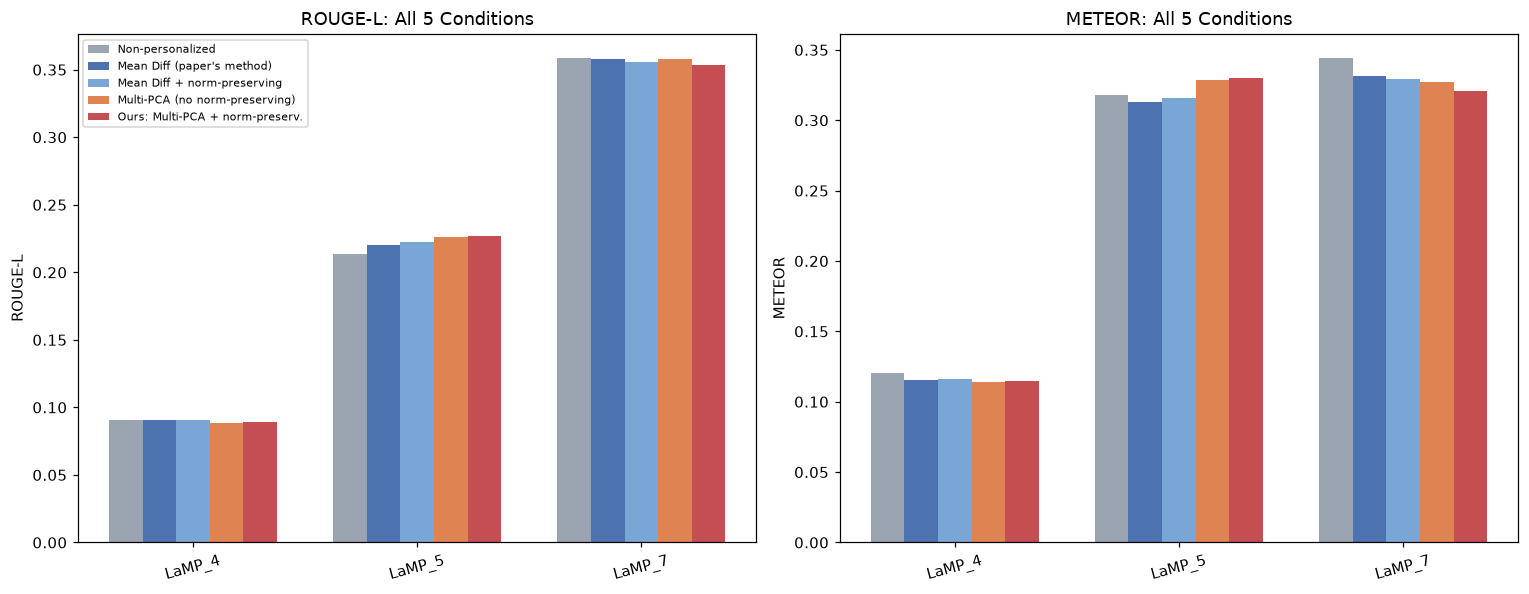

In [36]:
# Cell 6.4 — Grouped bar chart: ROUGE-L and METEOR, baseline + 4 conditions, per task
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
cond_colors = {
    "Non-personalized": "#9aa5b1",
    "Mean Diff (paper's method)": "#4c72b0",
    "Mean Diff + norm-preserving": "#7aa6d6",
    "Multi-PCA (no norm-preserving)": "#dd8452",
    "Ours: Multi-PCA + norm-preserv.": "#c44e52",
}
tasks_order = TASKS
x = np.arange(len(tasks_order))
width = 0.15

for ax, metric in zip(axes, ["ROUGE-L", "METEOR"]):
    for i, (cond_id, cond_label, _, _) in enumerate(CONDITIONS):
        vals = [
            ablation_table[(ablation_table["Task"] == t) & (ablation_table["Condition"] == cond_label)][metric].values[0]
            if len(ablation_table[(ablation_table["Task"] == t) & (ablation_table["Condition"] == cond_label)]) else 0
            for t in tasks_order
        ]
        offset = (i - 2) * width
        ax.bar(x + offset, vals, width, label=cond_label, color=cond_colors[cond_label])
    ax.set_xticks(x)
    ax.set_xticklabels(tasks_order, rotation=15)
    ax.set_ylabel(metric)
    ax.set_title(f"{metric}: All 5 Conditions")
    if metric == "ROUGE-L":
        ax.legend(fontsize=7, loc="upper left")

plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / "ablation_bar_chart.png", dpi=150)
plt.show()

In [ ]:
# Cell 6.5 — Explained variance of the PCA components, averaged across users --
# a sanity/interpretability check: how much style-variance does each component
# actually capture? (If component 1 dominates, multi-component gains may be small.)
variance_rows = []
for _, row in results_df.iterrows():
    pass  # vec_info is not stored per-row in checkpoints to keep file size down;
          # this is computed fresh below on a probe subset instead.

def probe_explained_variance(task, users, cfg, k_components, n_probe=20):
    layer_idx = cfg["layer"]
    max_history = MAX_HISTORY_PER_USER_BY_TASK[task]
    max_gen_tokens = MAX_GEN_TOKENS_PER_TASK[task]
    probe_ids = list(users.keys())[:n_probe]
    all_ratios = []
    for uid in probe_ids:
        u = users[uid]
        deltas = compute_user_deltas(model, tokenizer, u["history"], task, layer_idx,
                                      max_history=max_history, max_gen_tokens=max_gen_tokens)
        if deltas is None or deltas.shape[0] < 2:
            continue
        _, _, info = vectors_from_deltas(deltas, k=k_components)
        if "explained_variance_ratio" in info:
            all_ratios.append(info["explained_variance_ratio"])
    if not all_ratios:
        return None
    return np.mean(np.array(all_ratios), axis=0)

print("Probing explained variance (small subset, ~20 users/task -- this recomputes deltas, takes a minute)...")
fig, ax = plt.subplots(figsize=(7, 4.5))
for task in TASKS:
    avg_ratios = probe_explained_variance(task, eval_users[task], BEST_CONFIG[task], K_COMPONENTS)
    if avg_ratios is not None:
        ax.plot(range(1, len(avg_ratios) + 1), avg_ratios, marker="o", label=task)
ax.set_xlabel("PCA Component")
ax.set_ylabel("Avg. Explained Variance Ratio")
ax.set_title("How much style-variance does each component capture?")
ax.legend()
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / "explained_variance.png", dpi=150)
plt.show()

In [ ]:
# Cell 6.6 — Qualitative case study: all 5 outputs side by side, a few users per task
N_CASES = 3
for task in TASKS:
    print(f"\n{'='*20} {task} — sample cases {'='*20}")
    sample = results_df[results_df["task"] == task].head(N_CASES)
    for _, row in sample.iterrows():
        print(f"\n[user {row['user_id']}]")
        print(f"  gold          : {row['gold'][:70]!r}")
        print(f"  baseline      : {row['pred_baseline'][:70]!r}")
        print(f"  mean-diff     : {row['pred_mean_diff'][:70]!r}")
        print(f"  mean-diff+NP  : {row['pred_mean_diff_np'][:70]!r}")
        print(f"  multi-PCA     : {row['pred_multi_pca'][:70]!r}")
        print(f"  ours (full)   : {row['pred_ours'][:70]!r}")

## Part 7 — Save All Results

In [ ]:
# Cell 7.1 — Export everything
results_df.to_csv(CHECKPOINT_DIR / "full_results.csv", index=False)
ablation_table.to_csv(CHECKPOINT_DIR / "ablation_table.csv", index=False)
improvement_table.to_csv(CHECKPOINT_DIR / "improvement_table.csv", index=False)

with open(CHECKPOINT_DIR / "config.json", "w") as f:
    json.dump({"BEST_CONFIG": BEST_CONFIG, "K_COMPONENTS": K_COMPONENTS,
               "N_EVAL_USERS_CAP": N_EVAL_USERS_CAP}, f, indent=2)

print("Saved to:", CHECKPOINT_DIR.resolve())
print(" - full_results.csv          (every generation, all 5 conditions, per user)")
print(" - ablation_table.csv        (mean ROUGE-L/METEOR per condition per task)")
print(" - improvement_table.csv     (% improvement over baseline, all 4 steered conditions)")
print(" - config.json")
print(" - ablation_bar_chart.png")
print(" - explained_variance.png")